# Lab 4: Regression Analysis with Regularization Techniques
**Federico Poi**  
**MSCS-634-M50 — Advanced Big Data and Data Mining**  
**October 18, 2026**

I use the Diabetes dataset to compare simple, multiple, and polynomial regression, then test whether Ridge and Lasso improve the predictions. The main question is whether a more flexible model learns useful patterns or mostly fits noise. All reported test metrics use the same 89 held-out records.

## 1. Data preparation
The dataset has 442 patients and ten baseline measurements. The target is a quantitative measure of disease progression one year after baseline. I load the **unscaled** measurements with `scaled=False`, then fit scaling inside each training pipeline. This avoids using the dataset loader's full-dataset normalization in the evaluation.

Features: age, sex (encoded category), BMI, average blood pressure (`bp`), and six serum measurements (`s1`–`s6`). These include total cholesterol, LDL, HDL, total cholesterol/HDL ratio, log serum triglycerides, and blood glucose, respectively. The documentation notes that some feature meanings are not explicit in the original source; I keep the supplied names in the analysis. The target is a continuous score, not a diabetes diagnosis.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import warnings
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning

# Treat a failed Lasso convergence check as an error, rather than hiding it.
warnings.filterwarnings('error', category=ConvergenceWarning)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')
FIGURES = Path('screenshots')
FIGURES.mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)
def save_plot(name):
    plt.savefig(FIGURES / name, dpi=160, bbox_inches='tight')
    plt.show()

print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__}')
diabetes = load_diabetes(as_frame=True, scaled=False)
X, y = diabetes.data.copy(), diabetes.target.copy()
print(f'{len(X)} records; {X.shape[1]} predictors; target range {y.min():.0f}–{y.max():.0f}')
display(X.head())
display(pd.concat([X, y.rename('progression')], axis=1).describe().T)

Python 3.14.3 | scikit-learn 1.8.0
442 records; 10 predictors; target range 25–346


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,59.0000,2.0000,32.1000,101.0000,157.0000,93.2000,38.0000,4.0000,4.8598,87.0000
1,48.0000,1.0000,21.6000,87.0000,183.0000,103.2000,70.0000,3.0000,3.8918,69.0000
2,72.0000,2.0000,30.5000,93.0000,156.0000,93.6000,41.0000,4.0000,4.6728,85.0000
3,24.0000,1.0000,25.3000,84.0000,198.0000,131.4000,40.0000,5.0000,4.8903,89.0000
4,50.0000,1.0000,23.0000,101.0000,192.0000,125.4000,52.0000,4.0000,4.2905,80.0000


,count,mean,std,min,25%,50%,75%,max
age,442.0000,48.5181,13.1090,19.0000,38.2500,50.0000,59.0000,79.0000
sex,442.0000,1.4683,0.4996,1.0000,1.0000,1.0000,2.0000,2.0000
bmi,442.0000,26.3758,4.4181,18.0000,23.2000,25.7000,29.2750,42.2000
bp,442.0000,94.6470,13.8313,62.0000,84.0000,93.0000,105.0000,133.0000
s1,442.0000,189.1403,34.6081,97.0000,164.2500,186.0000,209.7500,301.0000
s2,442.0000,115.4391,30.4131,41.6000,96.0500,113.0000,134.5000,242.4000
s3,442.0000,49.7885,12.9342,22.0000,40.2500,48.0000,57.7500,99.0000
s4,442.0000,4.0702,1.2904,2.0000,3.0000,4.0000,5.0000,9.0900
s5,442.0000,4.6414,0.5224,3.2581,4.2767,4.6200,4.9972,6.1070
s6,442.0000,91.2602,11.4963,58.0000,83.2500,91.0000,98.0000,124.0000


,Count
Missing predictor values,0
Missing target values,0
Duplicate predictor rows,0
Nonfinite values,0


No imputation or row removal is needed. I keep all 442 records.


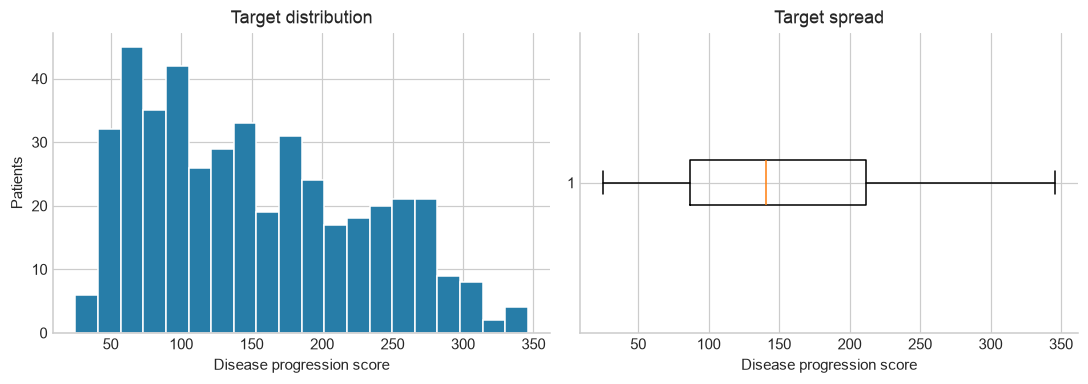

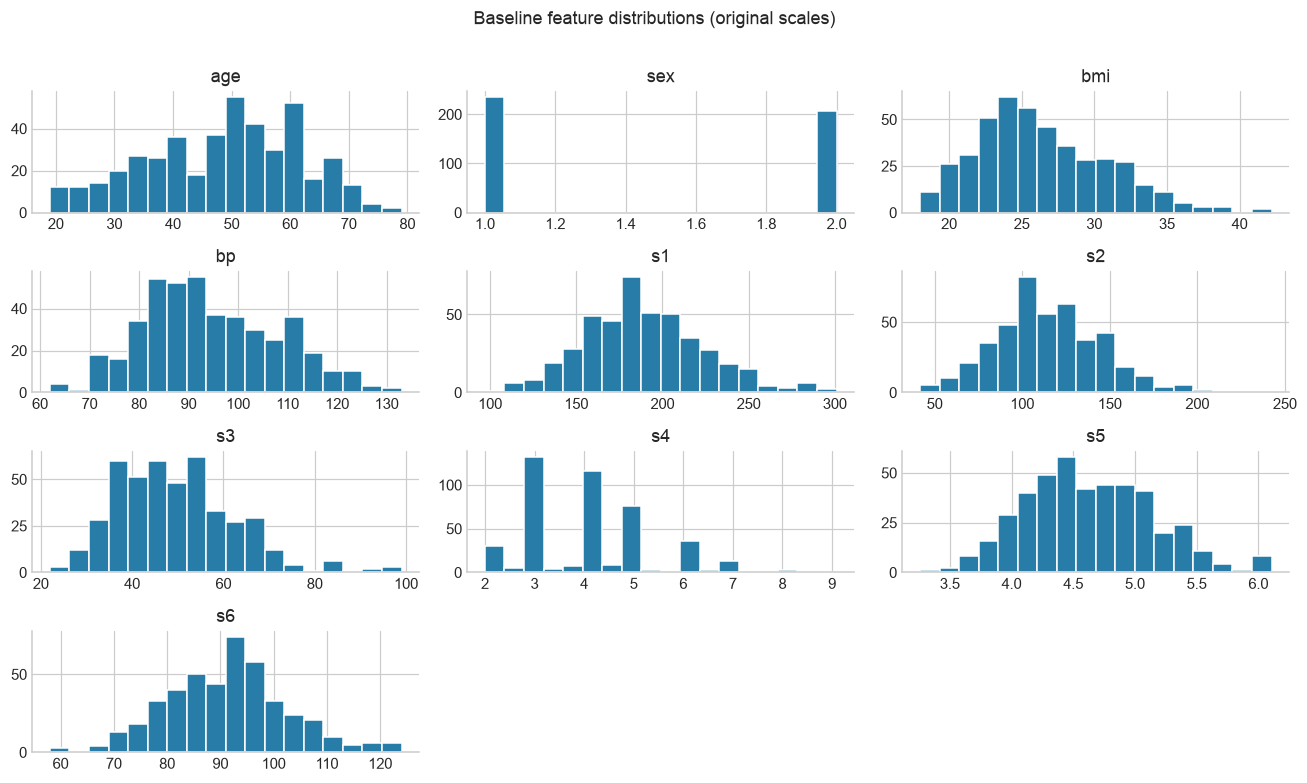

In [2]:
quality = pd.Series({
    'Missing predictor values': int(X.isna().sum().sum()),
    'Missing target values': int(y.isna().sum()),
    'Duplicate predictor rows': int(X.duplicated().sum()),
    'Nonfinite values': int((~np.isfinite(X.to_numpy())).sum() + (~np.isfinite(y)).sum())
})
display(quality.to_frame('Count'))
assert quality.eq(0).all()
print('No imputation or row removal is needed. I keep all 442 records.')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(y, bins=20, color='#277da8', edgecolor='white')
axes[0].set(xlabel='Disease progression score', ylabel='Patients', title='Target distribution')
axes[1].boxplot(y, orientation='horizontal')
axes[1].set(xlabel='Disease progression score', title='Target spread')
fig.tight_layout()
save_plot('01_target_distribution.png')

X.hist(bins=18, figsize=(12, 7), color='#277da8', edgecolor='white')
plt.suptitle('Baseline feature distributions (original scales)', y=1.01)
plt.tight_layout()
save_plot('02_feature_distributions.png')

### Split and evaluation plan
I reserve 20% for testing with `random_state=42`: 353 training records and 89 test records. BMI is chosen in advance as the single predictor because it has a straightforward interpretation. The multiple-regression models use all ten predictors.

Five shuffled folds of the training set are used for model comparisons and alpha selection. All fitted transformations stay inside the pipelines, so each fold learns its own scaling. Exploration of the full dataset above is descriptive; the correlation analysis below uses training records only. I do not choose features, degree, or alpha from test performance.

MAE is the average absolute error; MSE averages squared errors; RMSE is the square root of MSE and has the target's units. Lower is better for these three. R² compares prediction errors with a constant equal to the evaluated set's mean; higher is better, and it can be negative. A separate mean-only model below learns its constant from the training set.

Train: 353 | Test: 89


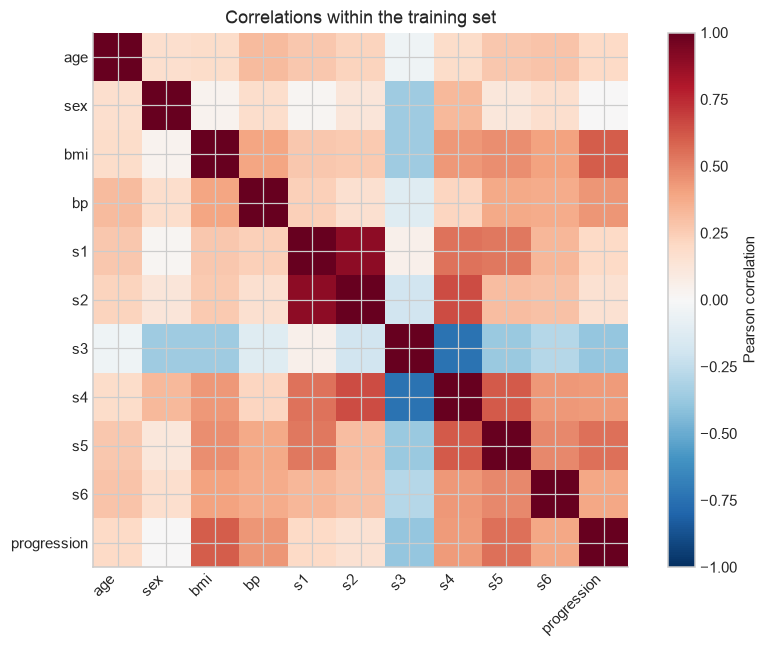

,Correlation
bmi,0.6048
s5,0.5522
bp,0.4448
s4,0.4251
s6,0.3904
s1,0.1995
age,0.1965
s2,0.1549
sex,0.0071
s3,-0.3840


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
assert set(X_train.index).isdisjoint(X_test.index)
print(f'Train: {len(X_train)} | Test: {len(X_test)}')
training_corr = pd.concat([X_train, y_train.rename('progression')], axis=1).corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(training_corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(11), training_corr.columns, rotation=45, ha='right')
ax.set_yticks(range(11), training_corr.index)
ax.set_title('Correlations within the training set')
fig.colorbar(im, ax=ax, label='Pearson correlation')
fig.tight_layout()
save_plot('03_training_correlations.png')
display(training_corr['progression'].drop('progression').sort_values(ascending=False).to_frame('Correlation'))

In [4]:
def regression_pipeline(estimator, degree=1):
    steps = [('scale', StandardScaler())]
    if degree > 1:
        steps += [('poly', PolynomialFeatures(degree=degree, include_bias=False)),
                  ('term_scale', StandardScaler())]
    return Pipeline(steps + [('model', estimator)])

def metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {'MAE': mean_absolute_error(actual, predicted), 'MSE': mse,
            'RMSE': np.sqrt(mse), 'R2': r2_score(actual, predicted)}

models, inputs, cv_rmse = {}, {}, {}
def fit_model(name, model, columns):
    train = X_train[columns]
    scores = cross_validate(model, train, y_train, cv=cv,
                            scoring='neg_mean_squared_error', return_train_score=True,
                            error_score='raise')
    # Root of mean fold MSE, consistent with GridSearchCV's selection criterion.
    cv_rmse[name] = np.sqrt(-scores['test_score'].mean())
    model.fit(train, y_train)
    models[name], inputs[name] = model, columns
    return scores

all_features = X.columns.tolist()
fit_model('Mean baseline', DummyRegressor(strategy='mean'), all_features)

{'fit_time': array([0.00025678, 0.00015807, 0.0001421 , 0.00013804, 0.00013995]),
 'score_time': array([1.60217285e-04, 1.04188919e-04, 9.79900360e-05, 9.60826874e-05,
        9.48905945e-05]),
 'test_score': array([-5762.51187931, -7151.87779188, -4781.25164429, -5979.01180562,
        -7008.62277341]),
 'train_score': array([-6174.98512399, -5815.5521352 , -6402.66899301, -6107.78501417,
        -5849.303375  ])}

## 2. Simple linear regression
This model fits one straight line, `progression = intercept + slope × BMI`. A train-fitted scaler changes the units used internally but does not change the class of straight lines the model can fit. The plot shows the fitted line together with the held-out observations; vertical differences from the line are prediction errors.

,MAE,MSE,RMSE,R2
Simple linear (BMI),52.2600,4061.8259,63.7325,0.2334


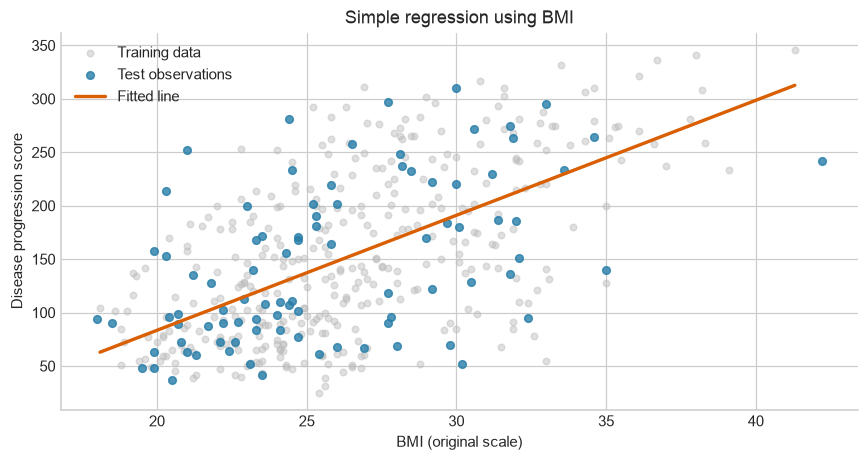

In [5]:
simple = regression_pipeline(LinearRegression())
fit_model('Simple linear (BMI)', simple, ['bmi'])
display(pd.DataFrame([metrics(y_test, simple.predict(X_test[['bmi']]))], index=['Simple linear (BMI)']))
line_x = pd.DataFrame({'bmi': np.linspace(X_train.bmi.min(), X_train.bmi.max(), 150)})
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.scatter(X_train.bmi, y_train, color='#bbbbbb', s=18, alpha=.45, label='Training data')
ax.scatter(X_test.bmi, y_test, color='#277da8', s=25, alpha=.8, label='Test observations')
ax.plot(line_x.bmi, simple.predict(line_x), color='#d95f02', lw=2.2, label='Fitted line')
ax.set(xlabel='BMI (original scale)', ylabel='Disease progression score', title='Simple regression using BMI')
ax.legend()
fig.tight_layout()
save_plot('04_simple_regression.png')

## 3. Multiple linear regression
I add the other nine measurements while keeping the same split. The fitted surface is linear in the ten predictors. An actual-versus-predicted plot makes this model comparable with later models: accurate predictions lie near the diagonal.

,MAE,MSE,RMSE,R2
Multiple linear,42.7941,2900.1936,53.8534,0.4526


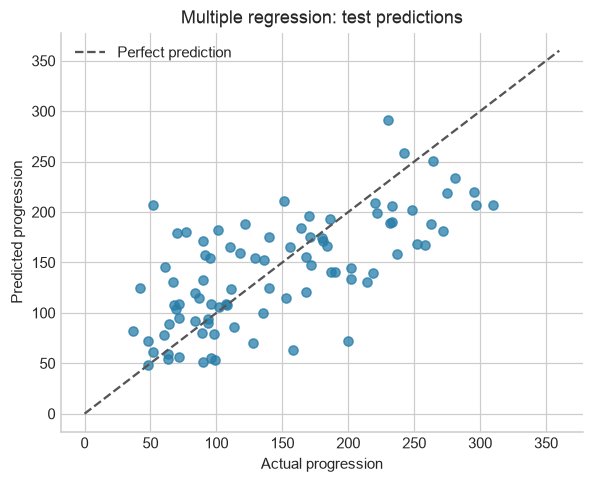

In [6]:
multiple = regression_pipeline(LinearRegression())
fit_model('Multiple linear', multiple, all_features)
pred = multiple.predict(X_test)
display(pd.DataFrame([metrics(y_test, pred)], index=['Multiple linear']))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(y_test, pred, color='#277da8', alpha=.75)
ax.plot([0, 360], [0, 360], '--', color='#555555', label='Perfect prediction')
ax.set(xlabel='Actual progression', ylabel='Predicted progression', title='Multiple regression: test predictions')
ax.legend()
fig.tight_layout()
save_plot('05_multiple_regression.png')

## 4. Polynomial regression and model complexity
I expand all ten predictors to degree 2 and degree 3, including interaction terms. Degree 1 is the multiple linear model. The expansions contain 65 and 285 columns, respectively, before the intercept. These are generated columns, not necessarily independent dimensions: for example, powers of the two-valued sex variable are redundant.

Scaling before expansion keeps the input magnitudes manageable; scaling after expansion puts the generated terms on comparable scales for the later penalties. Both scalers are fitted only within the training data or fold. I compare training error with validation error to assess whether added flexibility helps. The quadratic model is the fixed, modest expansion used for the regularization experiment; the cubic model is a complexity diagnostic.

,Generated columns,Fold train RMSE,Validation RMSE,Full train RMSE
Degree,,,,
1,10,53.3491,55.4449,53.5588
2,65,47.6395,62.6603,48.9197
3,285,11.0459,2612.2847,27.3060


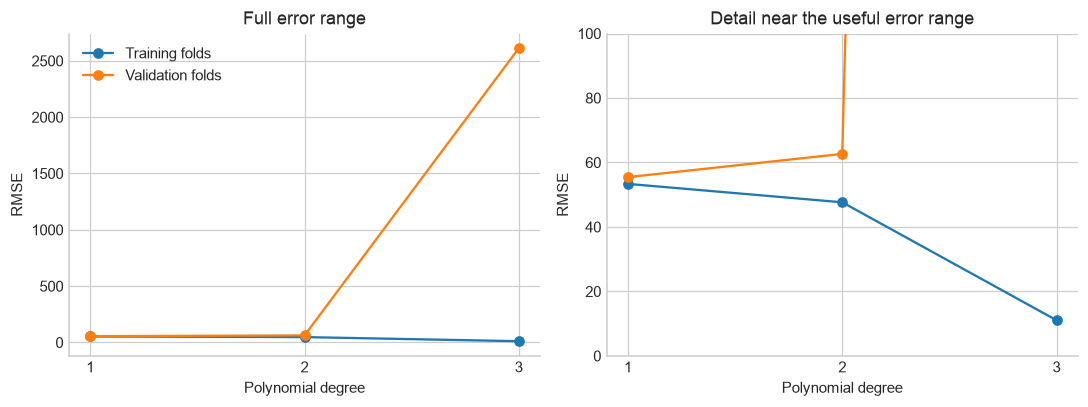

In [7]:
degree_rows = []
for degree in [1, 2, 3]:
    name = 'Multiple linear' if degree == 1 else f'Polynomial degree {degree}'
    if degree == 1:
        scores = cross_validate(multiple, X_train, y_train, cv=cv,
            scoring='neg_mean_squared_error', return_train_score=True, error_score='raise')
    else:
        scores = fit_model(name, regression_pipeline(LinearRegression(), degree), all_features)
    degree_rows.append({'Degree': degree,
        'Generated columns': 10 if degree == 1 else models[name].named_steps['poly'].n_output_features_,
        'Fold train RMSE': np.sqrt(-scores['train_score'].mean()),
        'Validation RMSE': np.sqrt(-scores['test_score'].mean()),
        'Full train RMSE': metrics(y_train, models[name].predict(X_train))['RMSE']})
degree_results = pd.DataFrame(degree_rows).set_index('Degree')
display(degree_results)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax in axes:
    ax.plot(degree_results.index, degree_results['Fold train RMSE'], 'o-', label='Training folds')
    ax.plot(degree_results.index, degree_results['Validation RMSE'], 'o-', label='Validation folds')
    ax.set(xlabel='Polynomial degree', ylabel='RMSE', xticks=[1, 2, 3])
axes[0].set_title('Full error range')
axes[0].legend()
axes[1].set(title='Detail near the useful error range', ylim=(0, 100))
fig.tight_layout()
save_plot('06_degree_overfitting.png')

## 5. Ridge and Lasso regression
Ridge adds an L2 penalty on squared coefficient magnitudes. Lasso adds an L1 penalty on absolute magnitudes and can set coefficients exactly to zero. Increasing alpha strengthens the penalty; very large values can leave a model too simple to capture the signal. The two estimators use differently scaled objective functions, so the same numeric alpha does not mean equal penalty strength across Ridge and Lasso.

I fit both methods to the original ten predictors and to the same quadratic features used above. This separates the effect of regularization from the effect of adding features. Alpha is selected by the lowest mean validation MSE in five folds. The Lasso grid starts at 0.1 because very weak penalties on the correlated polynomial terms gave convergence warnings in an initial check. I use 100,000 maximum iterations and make convergence warnings fail the run. No warning is suppressed.

,Alpha,Validation RMSE,Nonzero coefficients,Total coefficients
Model,,,,
Ridge,1.0000,55.4250,10,10
Lasso,0.1000,55.4038,10,10
Ridge + quadratic,100.0000,56.8939,65,65
Lasso + quadratic,4.6416,56.2443,11,65


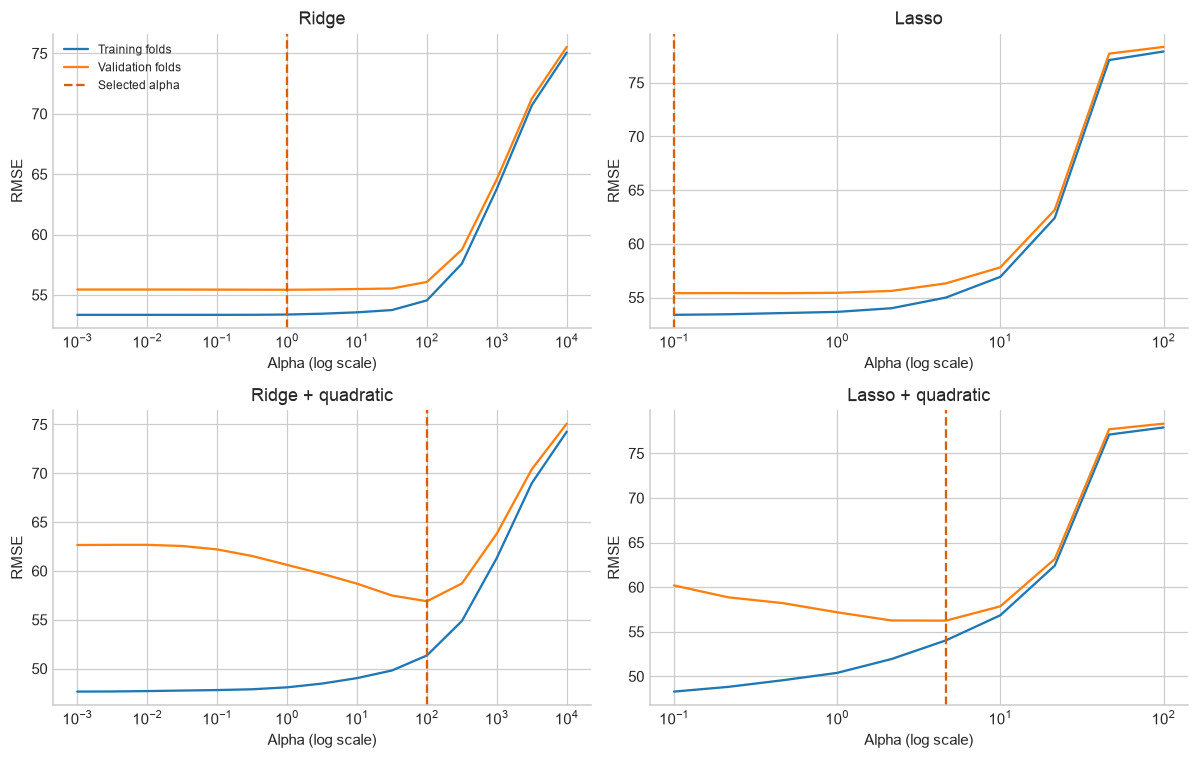

In [8]:
searches = {}
for degree, suffix in [(1, ''), (2, ' + quadratic')]:
    for label, estimator, alphas in [
        ('Ridge', Ridge(), np.logspace(-3, 4, 15)),
        ('Lasso', Lasso(max_iter=100000, tol=1e-5), np.logspace(-1, 2, 10))]:
        name = label + suffix
        search = GridSearchCV(regression_pipeline(estimator, degree),
            {'model__alpha': alphas}, scoring='neg_mean_squared_error', cv=cv,
            return_train_score=True, error_score='raise', n_jobs=1)
        search.fit(X_train, y_train)
        searches[name] = search
        models[name], inputs[name] = search.best_estimator_, all_features
        cv_rmse[name] = np.sqrt(-search.best_score_)
alpha_rows = []
for name, search in searches.items():
    coefficients = search.best_estimator_.named_steps['model'].coef_
    alpha_rows.append({'Model': name, 'Alpha': search.best_params_['model__alpha'],
        'Validation RMSE': cv_rmse[name], 'Nonzero coefficients': np.count_nonzero(coefficients),
        'Total coefficients': len(coefficients)})
alpha_results = pd.DataFrame(alpha_rows).set_index('Model')
display(alpha_results)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, search) in zip(axes.flat, searches.items()):
    values = search.cv_results_
    alphas = np.array(values['param_model__alpha'], dtype=float)
    ax.semilogx(alphas, np.sqrt(-values['mean_train_score']), label='Training folds')
    ax.semilogx(alphas, np.sqrt(-values['mean_test_score']), label='Validation folds')
    ax.axvline(search.best_params_['model__alpha'], color='#d95f02', ls='--', label='Selected alpha')
    ax.set(title=name, xlabel='Alpha (log scale)', ylabel='RMSE')
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
save_plot('07_alpha_validation.png')

,Multiple linear,Ridge,Lasso
age,1.7538,1.8073,1.7302
sex,-11.5118,-11.4482,-11.3165
bmi,25.6071,25.7327,25.8233
bp,16.8289,16.7343,16.6447
s1,-44.4489,-34.6720,-29.4350
s2,24.6410,17.0531,13.3349
s3,7.6770,3.3699,0.5817
s4,13.1388,11.7643,10.2467
s5,35.1612,31.3784,29.6619
s6,2.3514,2.4581,2.3932


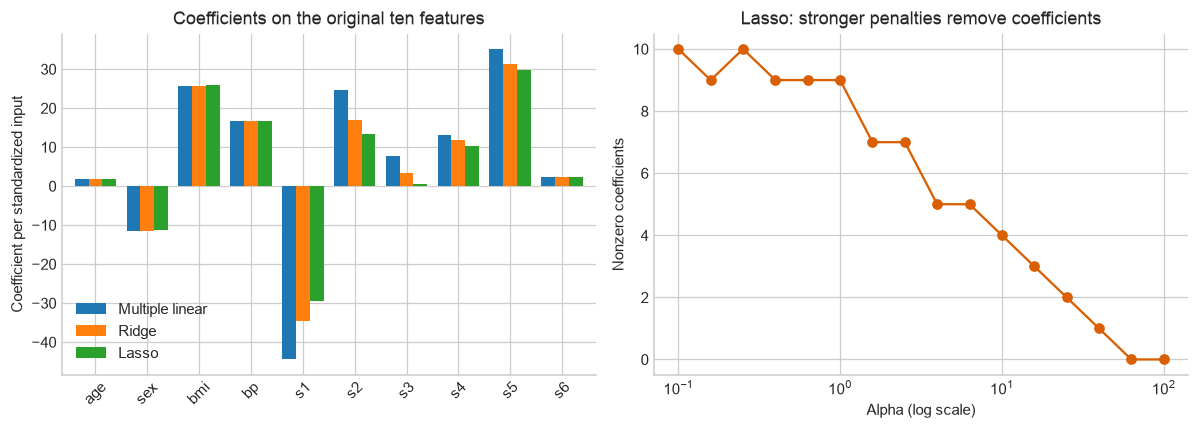

In [9]:
# Coefficients use standardized predictors; all three models share the same input units.
coefficient_table = pd.DataFrame({name: models[name].named_steps['model'].coef_
    for name in ['Multiple linear', 'Ridge', 'Lasso']}, index=all_features)
display(coefficient_table)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
coefficient_table.plot.bar(ax=axes[0], width=.8)
axes[0].set(title='Coefficients on the original ten features', ylabel='Coefficient per standardized input')
axes[0].tick_params(axis='x', rotation=45)
zero_counts = []
alpha_path = np.logspace(-1, 2, 16)
for alpha in alpha_path:
    path_model = regression_pipeline(Lasso(alpha=alpha, max_iter=100000, tol=1e-5))
    path_model.fit(X_train, y_train)
    zero_counts.append(np.count_nonzero(path_model.named_steps['model'].coef_))
axes[1].semilogx(alpha_path, zero_counts, 'o-', color='#d95f02')
axes[1].set(title='Lasso: stronger penalties remove coefficients', xlabel='Alpha (log scale)',
            ylabel='Nonzero coefficients', ylim=(-.5, 10.5))
fig.tight_layout()
save_plot('08_coefficients_and_sparsity.png')

## 6. Held-out model comparison
All model settings are now fixed. The table reports the four required test metrics, full-training RMSE, and training cross-validation RMSE. The mean baseline provides a reference for how much the predictors add. Cross-validation is used to choose a model; the lowest test error is reported as an observation, not a reason to retune it.

The degree and alpha validation figures above use training data only. Their validation scores are useful for selection, but the minimum across a search can be optimistic; the held-out evaluation is the separate check.

,Train RMSE,CV RMSE,MAE,MSE,RMSE,R2
Model,,,,,,
Mean baseline,77.9513,78.3368,64.0065,5361.5335,73.2225,-0.0120
Simple linear (BMI),62.0815,62.5232,52.2600,4061.8259,63.7325,0.2334
Multiple linear,53.5588,55.4449,42.7941,2900.1936,53.8534,0.4526
Polynomial degree 2,48.9197,62.6603,43.5817,3096.0283,55.6420,0.4156
Polynomial degree 3,27.3060,2612.2847,164.8539,82446.0488,287.1342,-14.5613
Ridge,53.5751,55.4250,42.8120,2892.0146,53.7775,0.4541
Lasso,53.5980,55.4038,42.8052,2884.6751,53.7092,0.4555
Ridge + quadratic,51.6497,56.8939,41.4705,2649.6123,51.4744,0.4999
Lasso + quadratic,54.3833,56.2443,42.5048,2685.6201,51.8230,0.4931


Selected by training CV: Lasso
Lowest observed test RMSE: Ridge + quadratic


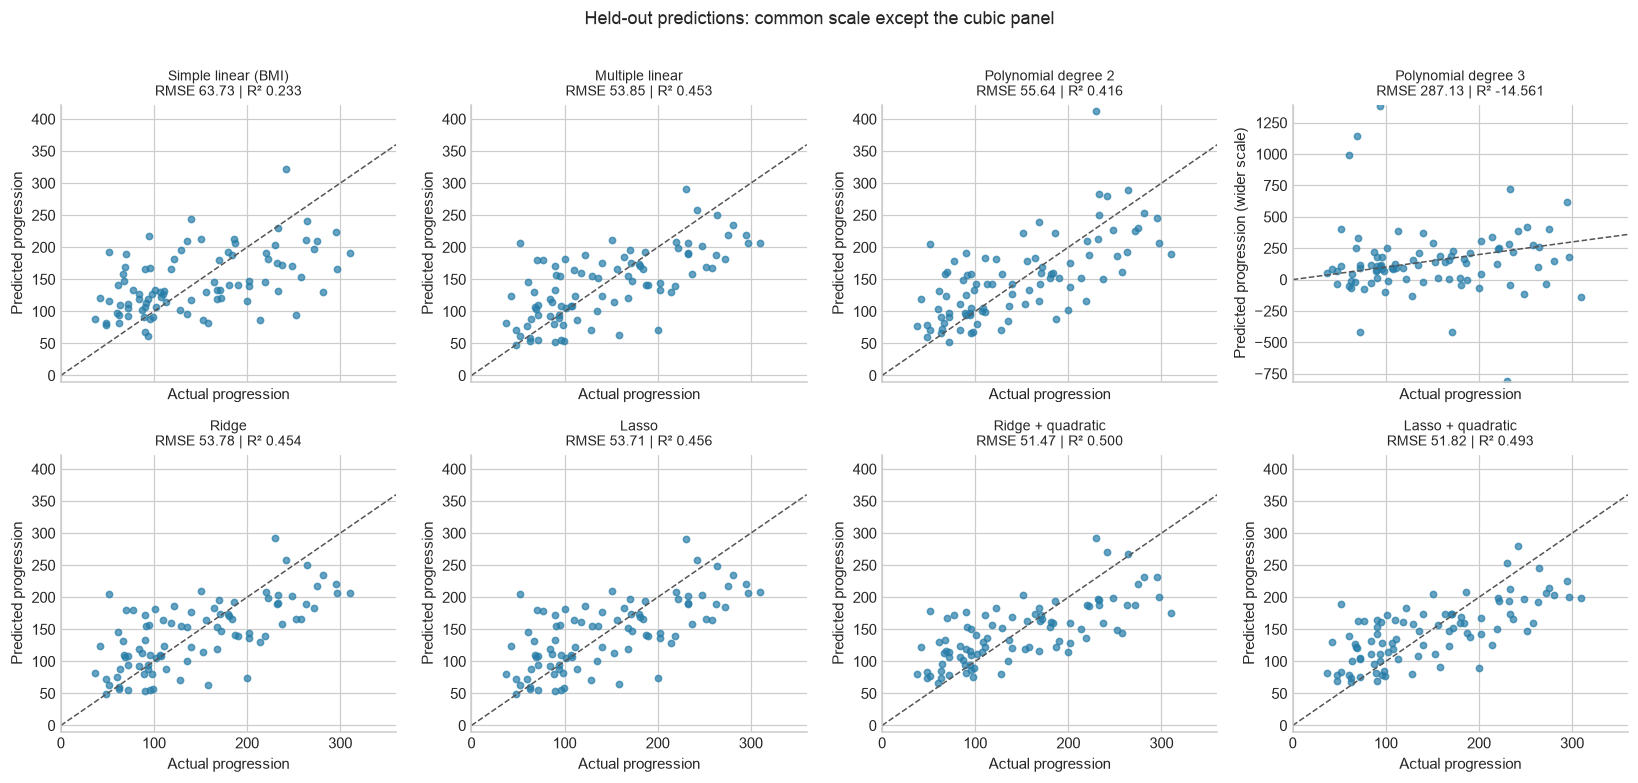

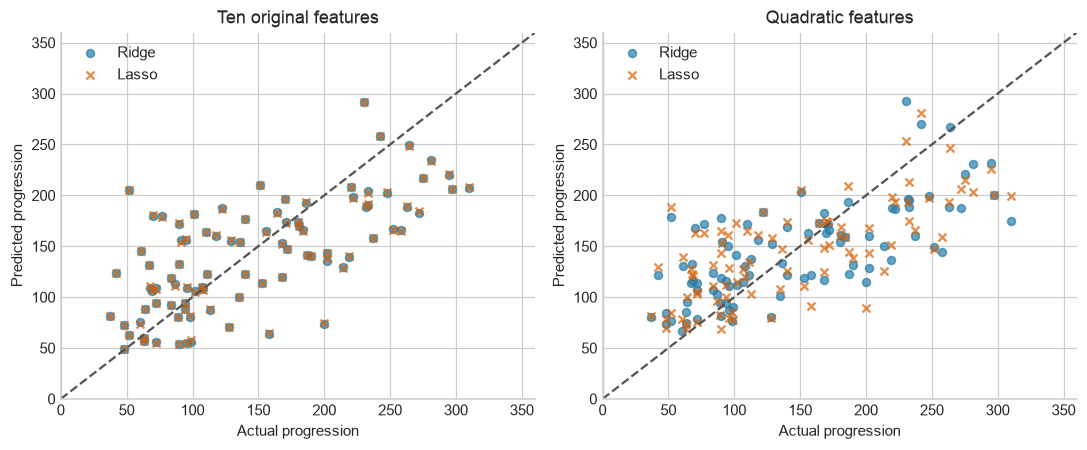

In [10]:
rows, predictions = [], {}
for name, model in models.items():
    columns = inputs[name]
    prediction = model.predict(X_test[columns])
    predictions[name] = prediction
    rows.append({'Model': name, 'Train RMSE': metrics(y_train, model.predict(X_train[columns]))['RMSE'],
                 'CV RMSE': cv_rmse[name], **metrics(y_test, prediction)})
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.round(4))
comparison.to_csv('results/model_comparison.csv')
degree_results.to_csv('results/polynomial_degrees.csv')
alpha_results.to_csv('results/selected_alphas.csv')
selected_name = comparison.drop(index='Mean baseline')['CV RMSE'].idxmin()
lowest_test_name = comparison['RMSE'].idxmin()
print('Selected by training CV:', selected_name)
print('Lowest observed test RMSE:', lowest_test_name)

fig, axes = plt.subplots(2, 4, figsize=(15, 7), sharex=True)
for ax, name in zip(axes.flat, [n for n in models if n != 'Mean baseline']):
    ax.scatter(y_test, predictions[name], s=17, alpha=.7, color='#277da8')
    ax.plot([0, 360], [0, 360], '--', color='#555555', lw=1)
    ax.set_title(f"{name}\nRMSE {comparison.loc[name, 'RMSE']:.2f} | R² {comparison.loc[name, 'R2']:.3f}", fontsize=9)
    ax.set(xlabel='Actual progression', ylabel='Predicted progression')
# Keep ordinary fits readable; label the cubic panel's necessary wider scale.
regular_predictions = np.concatenate([predictions[n] for n in models
                                      if n not in ['Mean baseline', 'Polynomial degree 3']])
normal_lo = min(0, regular_predictions.min()) - 10
normal_hi = max(360, regular_predictions.max()) + 10
for ax, name in zip(axes.flat, [n for n in models if n != 'Mean baseline']):
    ax.set_xlim(0, 360)
    if name == 'Polynomial degree 3':
        ax.set_ylim(min(0, predictions[name].min()) - 10,
                    max(360, predictions[name].max()) + 10)
        ax.set_ylabel('Predicted progression (wider scale)')
    else:
        ax.set_ylim(normal_lo, normal_hi)
fig.suptitle('Held-out predictions: common scale except the cubic panel', y=1.01)
fig.tight_layout()
save_plot('09_all_model_predictions.png')

# A closer comparison of the regularized models, using a common readable scale.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, suffix in zip(axes, ['', ' + quadratic']):
    for label, marker, color in [('Ridge', 'o', '#277da8'), ('Lasso', 'x', '#d95f02')]:
        ax.scatter(y_test, predictions[label + suffix], s=27, marker=marker, alpha=.7, color=color, label=label)
    ax.plot([0, 360], [0, 360], '--', color='#555555')
    ax.set(title='Ten original features' if not suffix else 'Quadratic features',
           xlabel='Actual progression', ylabel='Predicted progression', xlim=(0, 360), ylim=(0, 360))
    ax.legend()
fig.tight_layout()
save_plot('10_ridge_lasso_predictions.png')

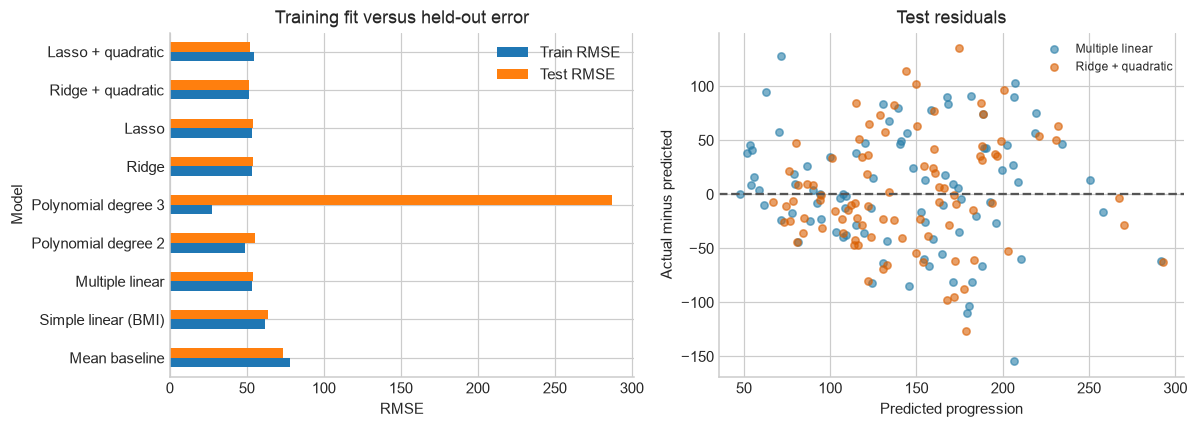

Checks passed: finite metrics, consistent RMSE/MSE, correct expansion sizes, and training-only scaling.


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
comparison[['Train RMSE', 'RMSE']].rename(columns={'RMSE': 'Test RMSE'}).plot.barh(ax=axes[0])
axes[0].set(xlabel='RMSE', title='Training fit versus held-out error')
for name, color in [('Multiple linear', '#277da8'), ('Ridge + quadratic', '#d95f02')]:
    residual = y_test.to_numpy() - predictions[name]
    axes[1].scatter(predictions[name], residual, s=23, alpha=.6, label=name, color=color)
axes[1].axhline(0, color='#555555', ls='--')
axes[1].set(xlabel='Predicted progression', ylabel='Actual minus predicted', title='Test residuals')
axes[1].legend(fontsize=8)
fig.tight_layout()
save_plot('11_errors_and_residuals.png')

assert np.isfinite(comparison.to_numpy()).all()
assert all(len(p) == len(y_test) for p in predictions.values())
assert np.allclose(comparison['RMSE'] ** 2, comparison['MSE'])
assert models['Polynomial degree 2'].named_steps['poly'].n_output_features_ == 65
assert models['Polynomial degree 3'].named_steps['poly'].n_output_features_ == 285
assert np.allclose(multiple.named_steps['scale'].mean_, X_train.mean())
summary = {'comparison': comparison.reset_index().to_dict(orient='records'),
           'alphas': alpha_results.reset_index().to_dict(orient='records'),
           'selected_by_cv': selected_name, 'lowest_test_rmse': lowest_test_name,
           'versions': {'python': sys.version.split()[0], 'sklearn': sklearn.__version__,
                        'numpy': np.__version__, 'pandas': pd.__version__}}
Path('results/run_summary.json').write_text(json.dumps(summary, indent=2))
print('Checks passed: finite metrics, consistent RMSE/MSE, correct expansion sizes, and training-only scaling.')

### Observations
BMI alone improves on the mean-only baseline: test RMSE falls from **73.22 to 63.73**, with R² **0.2334**. The scatter around its line remains wide. Using all ten measurements reduces RMSE further to **53.85** and raises R² to **0.4526**. BMI carries useful information, but one feature leaves much of the variation unexplained. BMI and `s5` have the strongest positive target correlations among the training predictors; several serum measurements are also correlated with each other.

Adding polynomial terms without a penalty does not help here. Quadratic training RMSE falls to **48.92**, but validation RMSE rises from **55.44 to 62.66** and test RMSE reaches **55.64**. The cubic model takes this much further: training RMSE is **27.31**, test RMSE is **287.13**, and test R² is **−14.5613**. Its validation RMSE is even larger. That is severe overfitting and numerical instability in a large, correlated expansion, not evidence of a better regression model.

Ridge and Lasso make only small changes on the original predictors. Their selected alphas are **1.0** and **0.1**, with test RMSE **53.78** and **53.71**, respectively. Lasso retains all ten coefficients at this selected alpha; it does not automatically produce a sparse model. Stronger penalties eventually remove coefficients and push validation error upward toward the mean-only model, illustrating underfitting.

The quadratic comparison shows a larger regularization effect. Ridge with alpha **100** reduces quadratic test RMSE from **55.64 to 51.47**, with R² **0.4999**. Quadratic Lasso with alpha **4.6416** gives RMSE **51.82**, with R² **0.4931**, and keeps only **11 of 65** coefficients. Ridge spreads the fit over the terms, while Lasso uses a much smaller subset.

**The selection rule matters.** Lasso on the original features has the lowest training CV RMSE, **55.40**, so it is the model selected by that rule. Quadratic Ridge has the lowest observed test error, but its CV RMSE is **56.89**. I report that difference rather than changing the choice after seeing test results. The linear CV scores are very close, and this single split cannot settle their ranking.

Even the lowest test error leaves substantial unexplained variation: an R² near 0.50 is useful relative to the baseline but far from a precise prediction for every patient. The residual plot still contains large positive and negative errors. More flexibility helps only when its variance is controlled; it does not remove the dataset's limited predictive signal.

### Decisions and limitations
I kept the notebook focused on the assigned models. BMI was fixed before fitting, and every model uses the same split. I used pipelines because scaling outside cross-validation would give the validation folds information from the rest of the training data. I did not remove patients simply because their values were unusual.

The cubic expansion is large relative to the 353 training records, and some generated columns are redundant. Its unstable predictions show why lower training error is not enough. Ridge stabilizes correlated coefficients; Lasso can remove terms, but which correlated term survives should not be read as a causal finding.

The results describe one split of a small dataset. Alpha tuning and model comparisons share the same training folds, and small differences between the linear models do not establish a reliable ranking. These models predict a progression score; the coefficients do not establish why a patient's condition changes.

## References and rerunning
- [scikit-learn: Diabetes dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)
- [scikit-learn: Linear models, Ridge, Lasso, and polynomial regression](https://scikit-learn.org/stable/modules/linear_model.html)
- [scikit-learn: Common pitfalls and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)

Install the packages in `requirements.txt`, open this notebook in Jupyter, and choose **Restart Kernel and Run All Cells**. The dataset is bundled with scikit-learn, so execution does not require a dataset download. Plot images and numeric results are regenerated in `screenshots/` and `results/`.